# Dimensionality Reduction — Implementation Cheatsheet

Theory: [dimensionality_reduction.md](dimensionality_reduction.md)

| # | Section | Data |
|---|---|---|
| 1 | PCA: why scaling matters | Customer Personality |
| 2 | PCA: how many components? | Customer Personality |
| 3 | PCA: interpreting components (loadings) | Customer Personality |
| 4 | PCA vs t-SNE for visualization | Handwritten digits (sklearn built-in) |
| 5 | t-SNE: perplexity | Handwritten digits |

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.datasets import load_digits

SEED = 1
cust = pd.read_csv("../data/customer_personality.csv", sep="\t").drop(columns=["ID", "Z_CostContact", "Z_Revenue"])
cust["Income"] = cust["Income"].fillna(cust["Income"].median())
X = cust.select_dtypes("number")
X.shape

(2240, 23)

## 1. PCA: why scaling matters
PCA looks for the directions of **largest variance**. Without scaling, the column with the biggest units (`Income`, in the tens of thousands) "wins" PC1 alone.

In [2]:
pca_raw = PCA().fit(X)
pca_scaled = PCA().fit(StandardScaler().fit_transform(X))
pd.DataFrame({
    "PC1 explained var (unscaled)": [pca_raw.explained_variance_ratio_[0]],
    "top feature in PC1 (unscaled)": [X.columns[np.abs(pca_raw.components_[0]).argmax()]],
    "PC1 explained var (scaled)": [pca_scaled.explained_variance_ratio_[0]],
    "top feature in PC1 (scaled)": [X.columns[np.abs(pca_scaled.components_[0]).argmax()]],
}).T

,0
PC1 explained var (unscaled),0.999812
top feature in PC1 (unscaled),Income
PC1 explained var (scaled),0.283267
top feature in PC1 (scaled),NumCatalogPurchases


Unscaled: PC1 \"explains\" almost everything, but it's just `Income`. **Always scale before PCA.**

## 2. PCA: how many components?

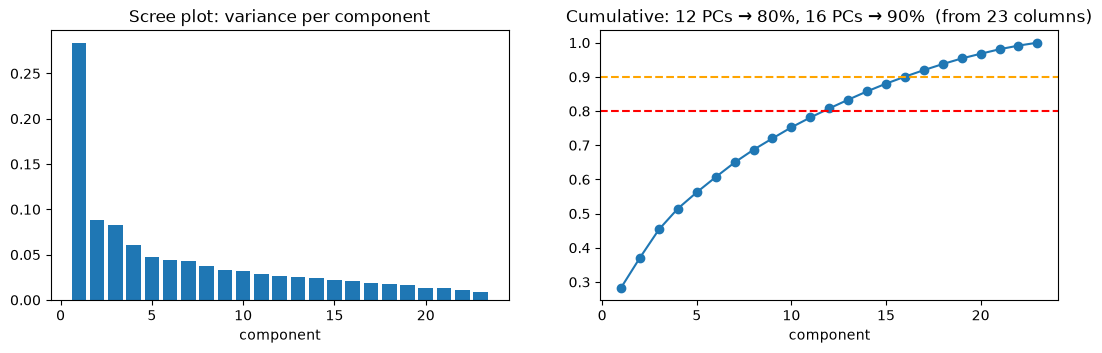

12 components keep 80%


In [3]:
X_s = StandardScaler().fit_transform(X)
pca = PCA().fit(X_s)
cum = pca.explained_variance_ratio_.cumsum()
n80, n90 = np.argmax(cum >= .80) + 1, np.argmax(cum >= .90) + 1

fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
ax[0].bar(range(1, len(cum) + 1), pca.explained_variance_ratio_); ax[0].set_title("Scree plot: variance per component")
ax[1].plot(range(1, len(cum) + 1), cum, marker="o"); ax[1].axhline(.8, color="r", ls="--"); ax[1].axhline(.9, color="orange", ls="--")
ax[1].set_title(f"Cumulative: {n80} PCs → 80%, {n90} PCs → 90%  (from {X.shape[1]} columns)")
for a in ax: a.set_xlabel("component")
plt.show()

# Shortcut: pass the variance you want instead of a number of components
print(PCA(n_components=0.80).fit(X_s).n_components_, "components keep 80%")

## 3. PCA: interpreting components (loadings)
Each PC is a weighted mix of the original columns. Big |weight| = that column drives the component.

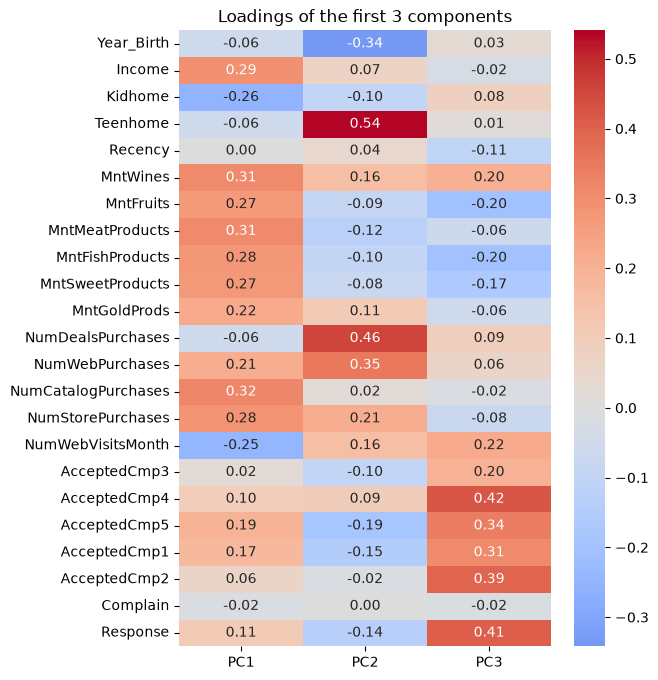

NumCatalogPurchases    0.32
MntMeatProducts        0.31
MntWines               0.31
Income                 0.29
NumStorePurchases      0.28
MntFishProducts        0.28
Name: PC1, dtype: float64

In [4]:
loadings = pd.DataFrame(pca.components_[:3].T, index=X.columns, columns=["PC1", "PC2", "PC3"])
plt.figure(figsize=(6, 8))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Loadings of the first 3 components"); plt.show()
loadings["PC1"].sort_values(key=abs, ascending=False).head(6).round(2)

**PC1 ≈ "spending power"**: income, spend on wine/meat, catalog & store purchases (positive) vs kids at home & web visits (negative).

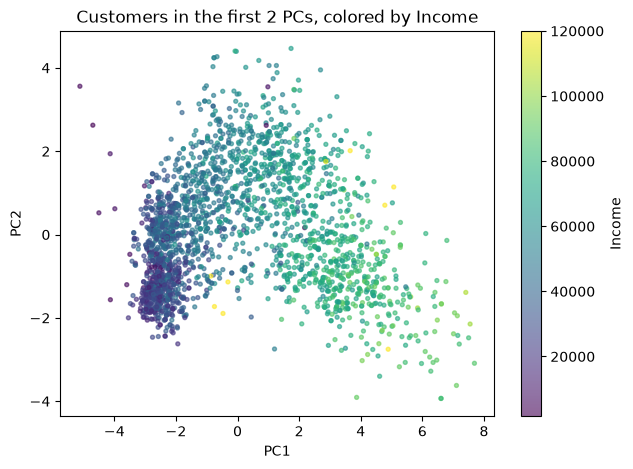

In [5]:
pcs = PCA(n_components=2).fit_transform(X_s)
plt.figure(figsize=(7, 5))
sc = plt.scatter(pcs[:, 0], pcs[:, 1], c=cust["Income"].clip(upper=120000), cmap="viridis", s=8, alpha=.6)
plt.colorbar(sc, label="Income"); plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Customers in the first 2 PCs, colored by Income"); plt.show()

## 4. PCA vs t-SNE for visualization
**Digits**: 1,797 images of 8×8 pixels = 64 features, 10 classes. Can we see the classes in 2D?

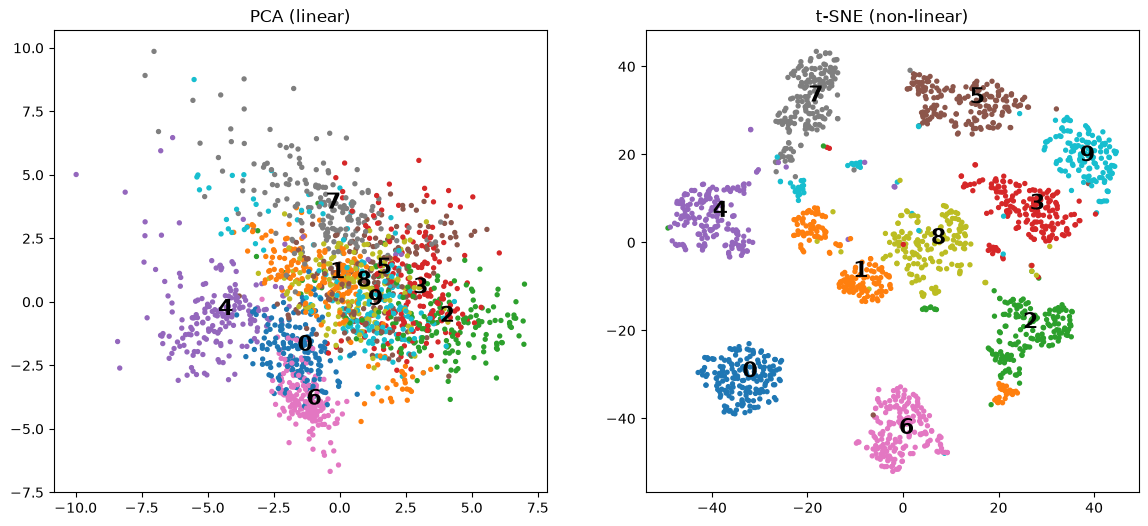

In [6]:
digits = load_digits()
Xd = StandardScaler().fit_transform(digits.data)
emb_pca = PCA(n_components=2, random_state=SEED).fit_transform(Xd)
emb_tsne = TSNE(n_components=2, perplexity=30, random_state=SEED).fit_transform(Xd)

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, emb, title in zip(ax, [emb_pca, emb_tsne], ["PCA (linear)", "t-SNE (non-linear)"]):
    sc = a.scatter(emb[:, 0], emb[:, 1], c=digits.target, cmap="tab10", s=8)
    for d in range(10):
        cx, cy = np.median(emb[digits.target == d], axis=0)
        a.text(cx, cy, str(d), fontsize=16, weight="bold")
    a.set_title(title)
plt.show()

PCA (linear) overlaps most digits. **t-SNE** separates them into clear groups because it preserves **local neighborhoods**.
⚠️ t-SNE is for **visualization only**: distances *between* clusters and cluster sizes are not meaningful, and it can't transform new data.

## 5. t-SNE: perplexity (≈ number of neighbors each point considers)

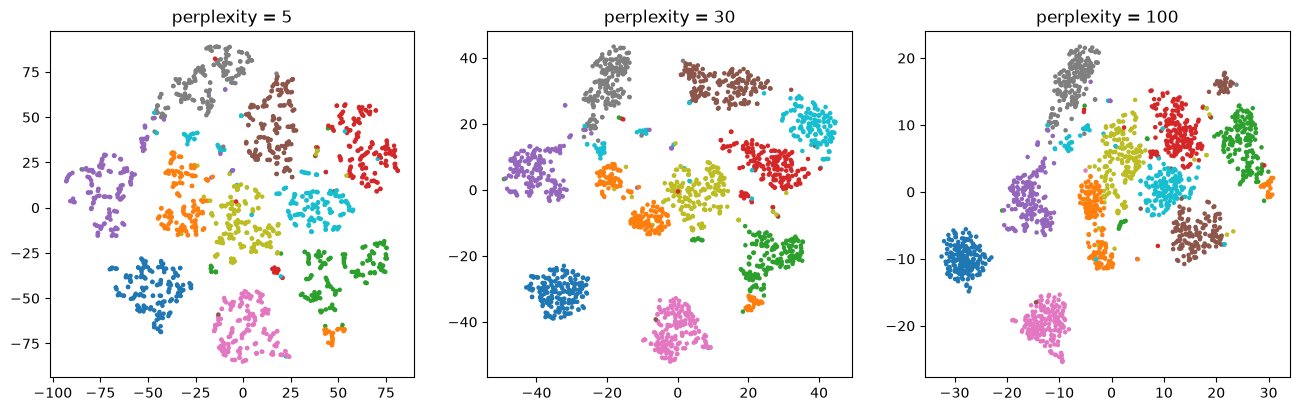

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, perp in zip(ax, [5, 30, 100]):
    emb = TSNE(n_components=2, perplexity=perp, random_state=SEED).fit_transform(Xd)
    a.scatter(emb[:, 0], emb[:, 1], c=digits.target, cmap="tab10", s=5); a.set_title(f"perplexity = {perp}")
plt.show()

Low perplexity → many small, fragmented clusters. High → more global structure, clusters merge. **5–50** is the usual range; try a few.